# End-to-End Benchmark: RASI Virtual Zarr vs Original NetCDF

This notebook benchmarks point time-series extraction for the **RASI ROUTING** dataset from:

- **Virtual Zarr** via Icechunk
- **Original NetCDF files on S3**

It follows the same benchmark structure as the earlier notebooks and measures:

1. **Access time**  
   Time to initialize repository access or discover files on S3

2. **Open time**  
   Time to open the dataset with xarray and subset the benchmark time range

3. **Selection time**  
   Time to select nearest-neighbor point(s)

4. **Load time**  
   Time to load the selected data into memory

5. **End-to-end time**  
   Access + open + selection + load

## Benchmark setup
- Benchmark cases: **1 point** and **5 points**
- Repeats: **1** by default
- Experiment: configurable (`HISTORICAL`, `SSP245`, `SSP585`)
- Variable: `RZSM_Percentiles`
- Percentile: **50** (median streamflow)
- Separate start/end dates for Virtual Zarr and NetCDF

**Author:** Siddharth Chaudhary


In [1]:
import time
import datetime as dt
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar
from IPython.display import display, Markdown

import icechunk
import s3fs
import fsspec
import netCDF4 as nc

pd.set_option("display.max_columns", None)


## 1. Benchmark configuration

In [2]:
experiment_ids = ["HISTORICAL", "SSP245", "SSP585"]
experiment_id = experiment_ids[0]   # change as needed

benchmark_cases = {
    "1 point": {
        "lon": [-100.0],
        "lat": [30.0],
    },
    "5 points": {
        "lon": [-100.0, -120.0, -90.0, -105.0, -75.0],
        "lat": [30.0, 45.0, 35.0, 40.0, 42.0],
    },
}

variable_name = "RZSM_Percentiles"
percentile_value = 50
repeats = 1

# Set benchmark windows independently if needed
vz_start = "1960-01-01"
vz_end   = "2014-12-31"

nc_start = "1960-01-01"
nc_end   = "2014-12-31"

print("Experiment:", experiment_id)
print("Variable:", variable_name)
print("Percentile:", percentile_value)
print("Repeats:", repeats)
print("Virtual Zarr period:", vz_start, "to", vz_end)
print("Original NetCDF period:", nc_start, "to", nc_end)


Experiment: HISTORICAL
Variable: RZSM_Percentiles
Percentile: 50
Repeats: 1
Virtual Zarr period: 1960-01-01 to 2014-12-31
Original NetCDF period: 1960-01-01 to 2014-12-31


## 2. Helper functions

In [3]:
def build_month_strings(start_date, end_date):
    months = pd.period_range(
        start=pd.Period(start_date, freq="M"),
        end=pd.Period(end_date, freq="M"),
        freq="M"
    )
    return [p.strftime("%Y%m") for p in months]


def list_rasi_netcdf_files_s3(start_date, end_date,
                              experiment_id,
                              bucket="nasa-waterinsight",
                              prefix_root="RASI/LSM"):
    fs = s3fs.S3FileSystem(anon=True)

    months = build_month_strings(start_date, end_date)

    files = []
    for month in months:
        pattern = (
            f"{bucket}/{prefix_root}/{experiment_id}/PERCENTILES/"
            f"RZSM_percentiles_{month}.nc"
        )
        matches = fs.glob(pattern)
        for m in matches:
            files.append(f"s3://{m}")

    files = sorted(files)

    if not files:
        raise FileNotFoundError("No RASI NetCDF files found for the requested date range.")

    return files


def open_rasi_virtual_zarr_with_timing(experiment_id, start_date=None, end_date=None):
    t0 = time.perf_counter()

    storage = icechunk.s3_storage(
        bucket="veda-data-store-staging",
        prefix=f"water-insight/virtual-zarr-store/RASI-icechunk-v2/LSM/{experiment_id}/",
        from_env=True,
    )

    chunk_url = "s3://veda-data-store-staging/water-insight/RASI/"
    virtual_credentials = icechunk.containers_credentials({
        chunk_url: icechunk.s3_credentials()
    })

    repo = icechunk.Repository.open(
        storage=storage,
        authorize_virtual_chunk_access=virtual_credentials,
    )

    session = repo.readonly_session("main")
    store = session.store
    t1 = time.perf_counter()

    ds = xr.open_zarr(store, consolidated=False, zarr_version=3, chunks={})

    if start_date is not None and end_date is not None:
        ds = ds.sel(time=slice(start_date, end_date))

    t2 = time.perf_counter()

    timing = {
        "source": "RASI Virtual Zarr",
        "access_time_sec": t1 - t0,
        "open_time_sec": t2 - t1,
        "open_total_time_sec": t2 - t0,
        "n_files": np.nan,
    }

    return ds, timing


def _normalize_rasi_netcdf_dataset(xr_ds):
    """
    Convert RASI monthly NetCDF into a dataset with a proper time dimension.
    """

    # Extract scalar date value
    raw_date = xr_ds["date"].values[0]

    # Convert integer YYYYMM → datetime
    time_value = pd.to_datetime(str(raw_date), format="%Y%m")

    # Drop useless dimensions/variables
    xr_ds = xr_ds.drop_vars("date")

    if "ncl0" in xr_ds.dims:
        xr_ds = xr_ds.squeeze("ncl0", drop=True)

    # Add real time dimension
    xr_ds = xr_ds.expand_dims(time=[time_value])

    return xr_ds

def open_rasi_netcdf_s3_with_timing(start_date, end_date, experiment_id):
    t0 = time.perf_counter()
    files = list_rasi_netcdf_files_s3(start_date, end_date, experiment_id)
    t1 = time.perf_counter()

    fs = fsspec.filesystem("s3", anon=True)

    datasets = []
    nc_handles = []

    for f in files:
        s3_path = f.replace("s3://", "")
        with fs.open(s3_path, "rb") as fp:
            raw = fp.read()

        # This pattern matches the approach that worked in prior exploration
        ds_nc4 = nc.Dataset("dummy", mode="r", memory=raw)
        nc_handles.append(ds_nc4)

        xr_ds = xr.open_dataset(xr.backends.NetCDF4DataStore(ds_nc4))
        xr_ds = _normalize_rasi_netcdf_dataset(xr_ds)
        datasets.append(xr_ds)

    # Sort monthly datasets by first timestamp, then concatenate along time
    
    datasets_sorted = sorted(
    datasets,
    key=lambda ds: pd.to_datetime(ds["time"].values[0])
    )

    ds_nc = xr.concat(
        datasets_sorted,
        dim="time",
        data_vars="all",
        coords="all",
        compat="override"
    )

    ds_nc = ds_nc.sortby("time")
    ds_nc = ds_nc.sel(time=slice(start_date, end_date))
    t2 = time.perf_counter()

    timing = {
        "source": "Original NetCDF",
        "access_time_sec": t1 - t0,
        "open_time_sec": t2 - t1,
        "open_total_time_sec": t2 - t0,
        "n_files": len(files),
    }

    return ds_nc, files, timing, datasets, nc_handles


def benchmark_timeseries(
    ds,
    lons,
    lats,
    var="RZSM_Percentiles",
    percentile=50,
    repeats=1,
):
    results = []
    loaded = None

    base = ds[var].sel(percentile=percentile)

    selection = {
        "lon": xr.DataArray(lons, dims=["points"]),
        "lat": xr.DataArray(lats, dims=["points"]),
    }

    for run in range(repeats):
        t0 = time.perf_counter()
        subset = base.sel(**selection, method="nearest")
        t1 = time.perf_counter()

        with ProgressBar():
            loaded = subset.load()
        t2 = time.perf_counter()

        results.append({
            "run": run + 1,
            "n_points": len(lons),
            "select_time_sec": t1 - t0,
            "load_time_sec": t2 - t1,
            "query_total_time_sec": t2 - t0,
            "n_time_steps": loaded.sizes.get("time", np.nan),
        })

    return pd.DataFrame(results), loaded


def benchmark_cases_for_source(
    ds,
    benchmark_cases,
    source_name,
    open_timing,
    var="RZSM_Percentiles",
    percentile=50,
    repeats=1,
):
    all_results = []
    loaded_outputs = {}

    for case_name, coords in benchmark_cases.items():
        print(f"Running {source_name} benchmark for: {case_name}")

        result_df, loaded = benchmark_timeseries(
            ds=ds,
            lons=coords["lon"],
            lats=coords["lat"],
            var=var,
            percentile=percentile,
            repeats=repeats,
        )

        result_df["case"] = case_name
        result_df["source"] = source_name
        result_df["access_time_sec"] = open_timing["access_time_sec"]
        result_df["open_time_sec"] = open_timing["open_time_sec"]
        result_df["open_total_time_sec"] = open_timing["open_total_time_sec"]
        result_df["end_to_end_time_sec"] = (
            result_df["open_total_time_sec"] + result_df["query_total_time_sec"]
        )
        result_df["n_files"] = open_timing.get("n_files", np.nan)

        all_results.append(result_df)
        loaded_outputs[(source_name, case_name)] = loaded

    benchmark_df = pd.concat(all_results, ignore_index=True)
    return benchmark_df, loaded_outputs


def summarize_results(benchmark_df):
    return (
        benchmark_df
        .groupby(["source", "case", "n_points"], as_index=False)
        .agg(
            n_files=("n_files", "first"),
            access_time_sec=("access_time_sec", "first"),
            open_time_sec=("open_time_sec", "first"),
            open_total_time_sec=("open_total_time_sec", "first"),
            mean_select_time_sec=("select_time_sec", "mean"),
            mean_load_time_sec=("load_time_sec", "mean"),
            mean_query_time_sec=("query_total_time_sec", "mean"),
            mean_end_to_end_time_sec=("end_to_end_time_sec", "mean"),
            n_time_steps=("n_time_steps", "first"),
        )
    )


## 3. Open datasets

In [4]:
# Virtual Zarr
ds_vz, vz_timing = open_rasi_virtual_zarr_with_timing(
    experiment_id=experiment_id,
    start_date=vz_start,
    end_date=vz_end,
)

print("RASI Virtual Zarr timing:")
display(pd.DataFrame([vz_timing]))
print("Virtual Zarr dims:", ds_vz.dims)
print("Virtual Zarr coords:", list(ds_vz.coords))
print("Virtual Zarr vars:", list(ds_vz.data_vars))


/tmp/ipykernel_137/2002258477.py:59: FutureWarning: zarr_version is deprecated, use zarr_format
  ds = xr.open_zarr(store, consolidated=False, zarr_version=3, chunks={})


RASI Virtual Zarr timing:


,source,access_time_sec,open_time_sec,open_total_time_sec,n_files
0,RASI Virtual Zarr,0.204865,3.016286,3.221151,NaN


Virtual Zarr dims: FrozenMappingWarningOnValuesAccess({'time': 660, 'percentile': 5, 'lat': 152, 'lon': 132})
Virtual Zarr coords: ['time', 'lon', 'percentile', 'lat']
Virtual Zarr vars: ['AvgSurfT_Percentiles', 'Qsb_Percentiles', 'SWE_Percentiles', 'Snowf_percentiles', 'TotalPrecip_Percentiles', 'RZSM_Percentiles', 'SnowDepth_Percentiles', 'Qs_Percentiles']


In [5]:
# Original NetCDF on S3
ds_nc, netcdf_files, nc_timing, nc_xarray_datasets, nc_handles = open_rasi_netcdf_s3_with_timing(
    start_date=nc_start,
    end_date=nc_end,
    experiment_id=experiment_id,
)

print("Original NetCDF timing:")
display(pd.DataFrame([nc_timing]))
print("NetCDF files used:")
for f in netcdf_files:
    print(f)
print("Original NetCDF dims:", ds_nc.dims)
print("Original NetCDF coords:", list(ds_nc.coords))
print("Original NetCDF vars:", list(ds_nc.data_vars))


Original NetCDF timing:


,source,access_time_sec,open_time_sec,open_total_time_sec,n_files
0,Original NetCDF,8.845641,81.366121,90.211763,660


NetCDF files used:
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196001.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196002.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196003.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196004.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196005.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196006.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196007.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196008.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196009.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196010.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196011.nc
s3://nasa-waterinsight/RASI/LSM/HISTORICAL/PERCENTILES/RZSM_percentiles_196012.

## 4. Run the end-to-end benchmark

In [8]:
benchmark_vz_df, loaded_outputs_vz = benchmark_cases_for_source(
    ds=ds_vz,
    benchmark_cases=benchmark_cases,
    source_name="RASI Virtual Zarr",
    open_timing=vz_timing,
    var=variable_name,
    percentile=percentile_value,
    repeats=repeats,
)

benchmark_nc_df, loaded_outputs_nc = benchmark_cases_for_source(
    ds=ds_nc,
    benchmark_cases=benchmark_cases,
    source_name="Original NetCDF",
    open_timing=nc_timing,
    var=variable_name,
    percentile=percentile_value,
    repeats=repeats,
)

comparison_df = pd.concat([benchmark_vz_df, benchmark_nc_df], ignore_index=True)

display(Markdown("### Combined per-run benchmark results"))
display(comparison_df)


Running RASI Virtual Zarr benchmark for: 1 point
[########################################] | 100% Completed | 1.44 sms
Running RASI Virtual Zarr benchmark for: 5 points
[########################################] | 100% Completed | 1.44 sms
Running Original NetCDF benchmark for: 1 point
Running Original NetCDF benchmark for: 5 points


### Combined per-run benchmark results

,run,n_points,select_time_sec,load_time_sec,query_total_time_sec,n_time_steps,case,source,access_time_sec,open_time_sec,open_total_time_sec,end_to_end_time_sec,n_files
0,1,1,0.018154,1.686319,1.704473,660,1 point,RASI Virtual Zarr,0.204865,3.016286,3.221151,4.925624,NaN
1,1,5,0.018313,1.503183,1.521496,660,5 points,RASI Virtual Zarr,0.204865,3.016286,3.221151,4.742647,NaN
2,1,1,0.001255,0.000151,0.001406,660,1 point,Original NetCDF,8.845641,81.366121,90.211763,90.213169,660.0
3,1,5,0.001294,0.000154,0.001448,660,5 points,Original NetCDF,8.845641,81.366121,90.211763,90.213211,660.0


In [9]:
summary_df = summarize_results(comparison_df)

display(Markdown("### Summary results"))
display(summary_df)


### Summary results

,source,case,n_points,n_files,access_time_sec,open_time_sec,open_total_time_sec,mean_select_time_sec,mean_load_time_sec,mean_query_time_sec,mean_end_to_end_time_sec,n_time_steps
0,Original NetCDF,1 point,1,660.0,8.845641,81.366121,90.211763,0.001255,0.000151,0.001406,90.213169,660
1,Original NetCDF,5 points,5,660.0,8.845641,81.366121,90.211763,0.001294,0.000154,0.001448,90.213211,660
2,RASI Virtual Zarr,1 point,1,NaN,0.204865,3.016286,3.221151,0.018154,1.686319,1.704473,4.925624,660
3,RASI Virtual Zarr,5 points,5,NaN,0.204865,3.016286,3.221151,0.018313,1.503183,1.521496,4.742647,660


## 5. Benchmark plots

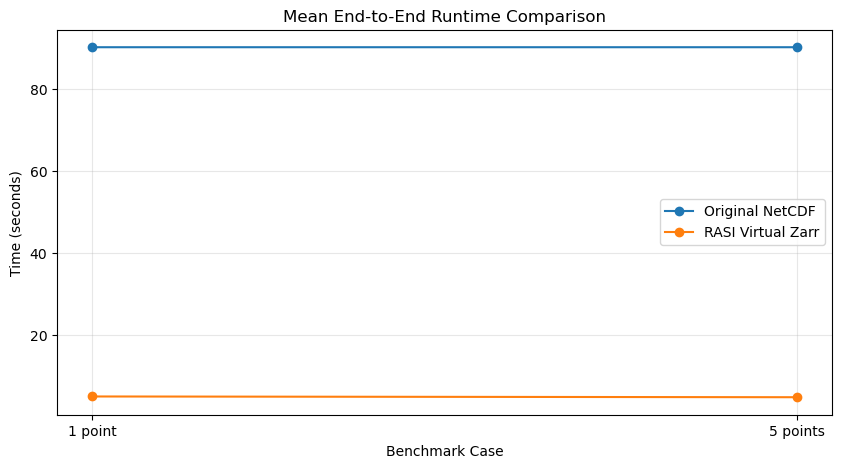

In [10]:
# Mean end-to-end runtime comparison
plt.figure(figsize=(10, 5))
for source_name in summary_df["source"].unique():
    sub = summary_df[summary_df["source"] == source_name]
    plt.plot(sub["case"], sub["mean_end_to_end_time_sec"], marker="o", label=source_name)

plt.title("Mean End-to-End Runtime Comparison")
plt.xlabel("Benchmark Case")
plt.ylabel("Time (seconds)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


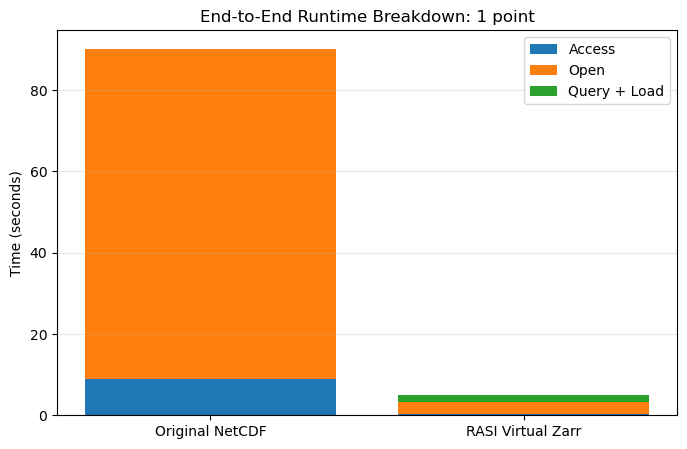

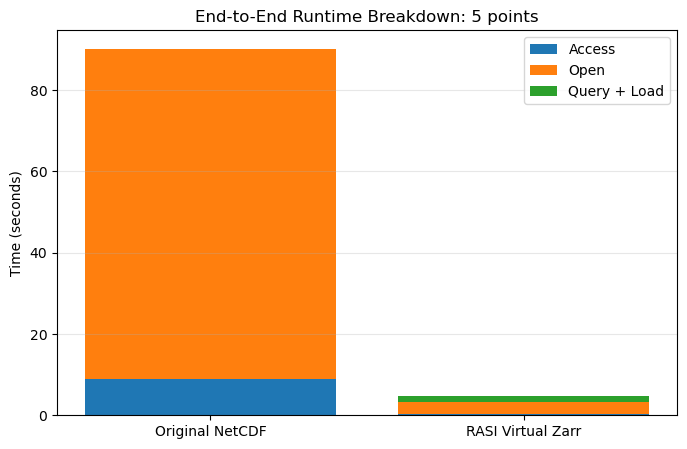

In [11]:
# Runtime breakdown by case
for case_name in summary_df["case"].unique():
    sub = summary_df[summary_df["case"] == case_name].copy()

    plt.figure(figsize=(8, 5))
    plt.bar(sub["source"], sub["access_time_sec"], label="Access")
    plt.bar(
        sub["source"],
        sub["open_time_sec"],
        bottom=sub["access_time_sec"],
        label="Open"
    )
    plt.bar(
        sub["source"],
        sub["mean_query_time_sec"],
        bottom=sub["access_time_sec"] + sub["open_time_sec"],
        label="Query + Load"
    )

    plt.title(f"End-to-End Runtime Breakdown: {case_name}")
    plt.ylabel("Time (seconds)")
    plt.grid(True, axis="y", alpha=0.3)
    plt.legend()
    plt.show()


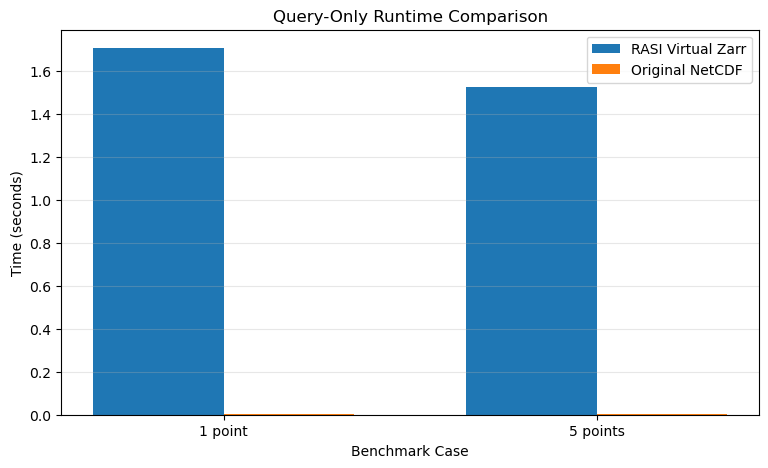

In [12]:
# Query-only runtime comparison
plt.figure(figsize=(9, 5))

cases = list(summary_df["case"].unique())
x = np.arange(len(cases))
width = 0.35

vz_vals = [
    summary_df[
        (summary_df["source"] == "RASI Virtual Zarr") &
        (summary_df["case"] == c)
    ]["mean_query_time_sec"].iloc[0]
    for c in cases
]
nc_vals = [
    summary_df[
        (summary_df["source"] == "Original NetCDF") &
        (summary_df["case"] == c)
    ]["mean_query_time_sec"].iloc[0]
    for c in cases
]

plt.bar(x - width/2, vz_vals, width, label="RASI Virtual Zarr")
plt.bar(x + width/2, nc_vals, width, label="Original NetCDF")

plt.xticks(x, cases)
plt.title("Query-Only Runtime Comparison")
plt.xlabel("Benchmark Case")
plt.ylabel("Time (seconds)")
plt.grid(True, axis="y", alpha=0.3)
plt.legend()
plt.show()


## 6. Histograms of extracted values

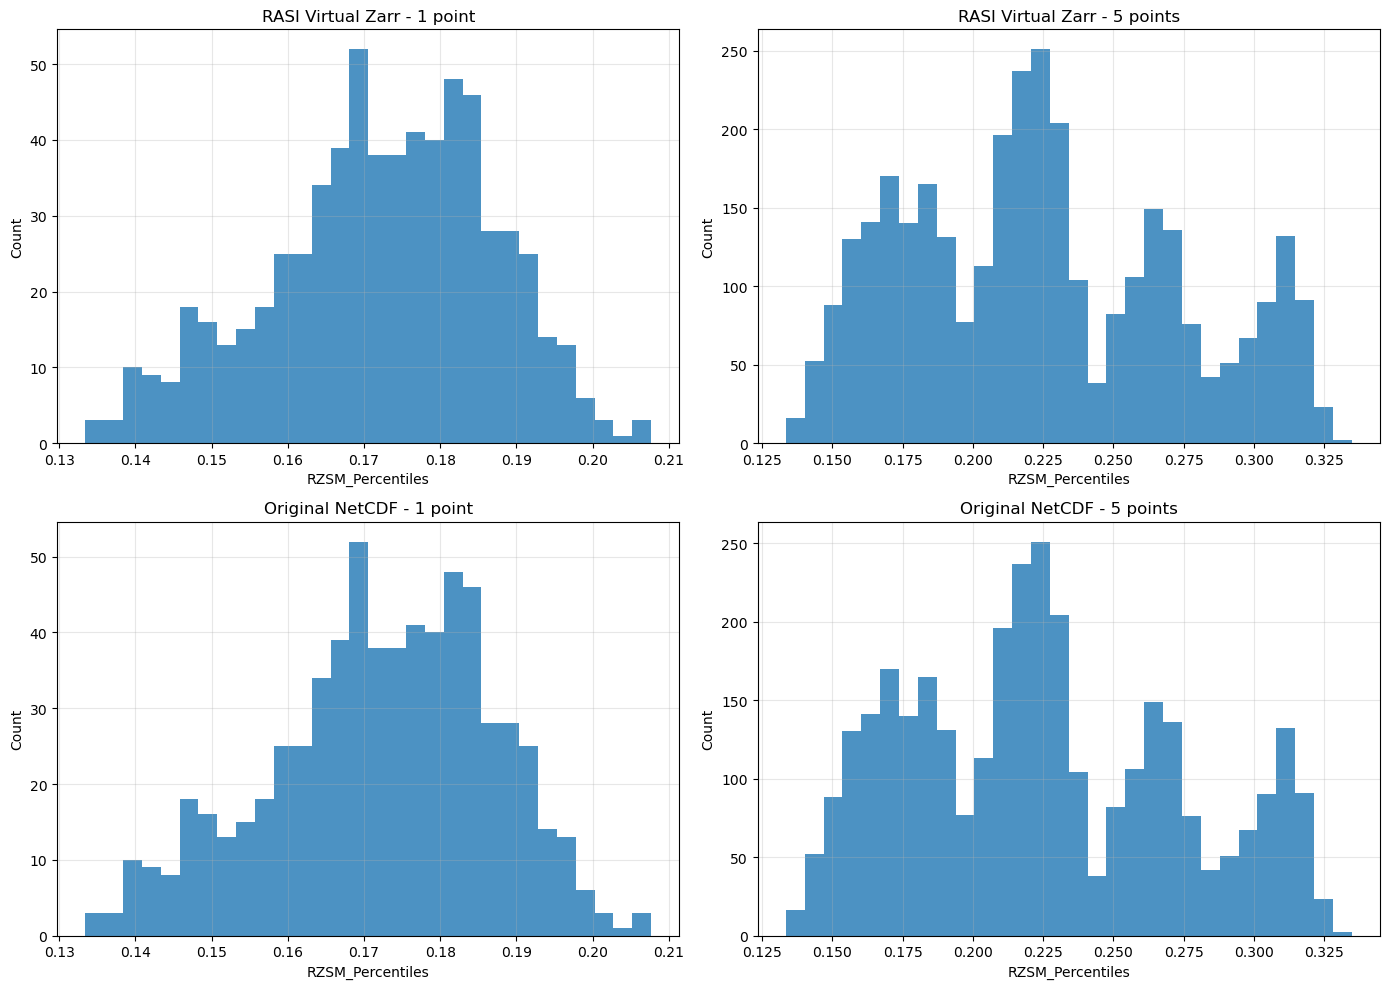

In [13]:
loaded_outputs = {}
loaded_outputs.update(loaded_outputs_vz)
loaded_outputs.update(loaded_outputs_nc)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

plot_order = [
    ("RASI Virtual Zarr", "1 point"),
    ("RASI Virtual Zarr", "5 points"),
    ("Original NetCDF", "1 point"),
    ("Original NetCDF", "5 points"),
]

for ax, key in zip(axes, plot_order):
    arr = loaded_outputs[key].values.ravel()
    arr = arr[np.isfinite(arr)]

    ax.hist(arr, bins=30, alpha=0.8)
    ax.set_title(f"{key[0]} - {key[1]}")
    ax.set_xlabel(variable_name)
    ax.set_ylabel("Count")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Example time series

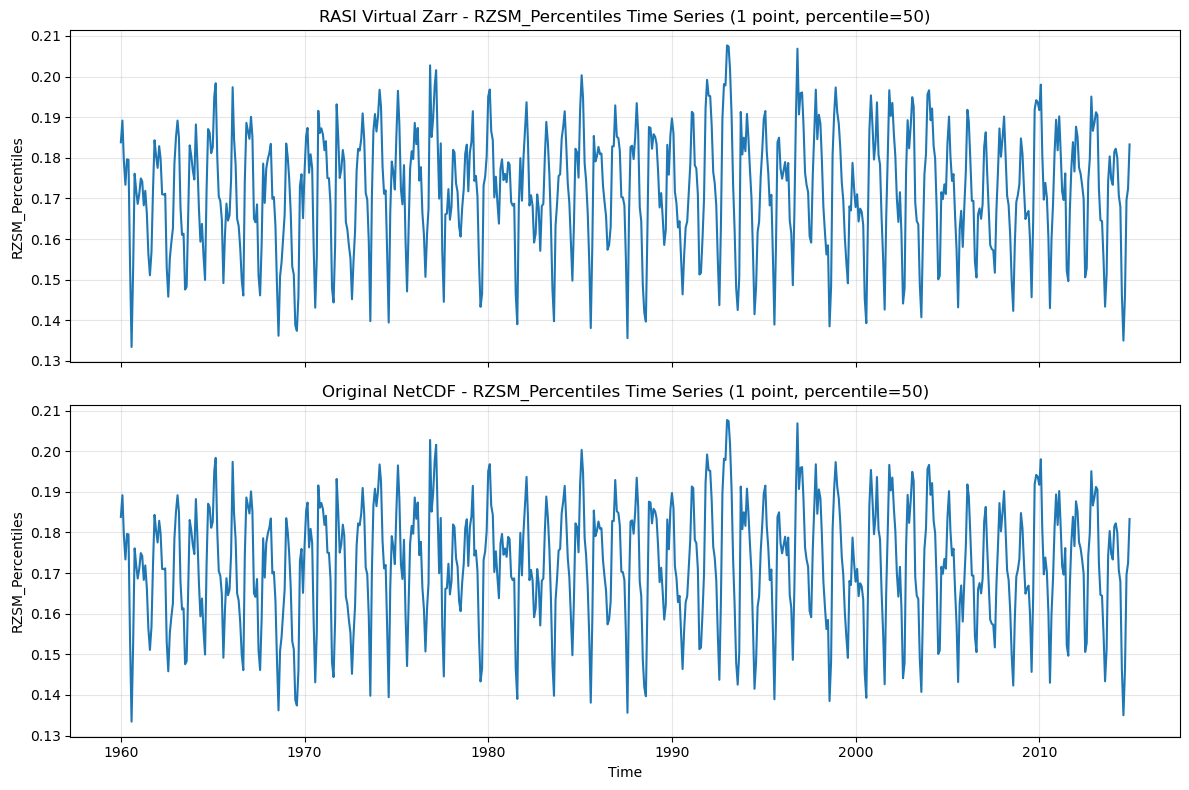

In [14]:
example_vz = loaded_outputs_vz[("RASI Virtual Zarr", "1 point")].to_pandas()
example_nc = loaded_outputs_nc[("Original NetCDF", "1 point")].to_pandas()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(example_vz.index, example_vz.values)
axes[0].set_title(f"RASI Virtual Zarr - {variable_name} Time Series (1 point, percentile={percentile_value})")
axes[0].set_ylabel(variable_name)
axes[0].grid(True, alpha=0.3)

axes[1].plot(example_nc.index, example_nc.values)
axes[1].set_title(f"Original NetCDF - {variable_name} Time Series (1 point, percentile={percentile_value})")
axes[1].set_xlabel("Time")
axes[1].set_ylabel(variable_name)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Cleanup

In [15]:
# Close underlying NetCDF resources when you're done
for ds_tmp in nc_xarray_datasets:
    ds_tmp.close()

for h in nc_handles:
    h.close()

print("Closed NetCDF resources.")


Closed NetCDF resources.


In [16]:
def compare_times(netcdf_time, virtual_time):
    ratio = netcdf_time / virtual_time
    if ratio >= 1:
        return f"{ratio:.1f}× faster"
    else:
        return f"{(1/ratio):.1f}× slower"

vz_1 = summary_df[(summary_df["source"] == "RASI Virtual Zarr") & (summary_df["case"] == "1 point")].iloc[0]
vz_5 = summary_df[(summary_df["source"] == "RASI Virtual Zarr") & (summary_df["case"] == "5 points")].iloc[0]

nc_1 = summary_df[(summary_df["source"] == "Original NetCDF") & (summary_df["case"] == "1 point")].iloc[0]
nc_5 = summary_df[(summary_df["source"] == "Original NetCDF") & (summary_df["case"] == "5 points")].iloc[0]

print("\n ===== BENCHMARK SUMMARY =====\n")

print("End-to-End Performance")
print(f"1 point: {compare_times(nc_1['mean_end_to_end_time_sec'], vz_1['mean_end_to_end_time_sec'])}")
print(f"5 points: {compare_times(nc_5['mean_end_to_end_time_sec'], vz_5['mean_end_to_end_time_sec'])}")

print("Dataset Open Performance")
print(compare_times(nc_1['open_total_time_sec'], vz_1['open_total_time_sec']))

print("Query Performance")
print(f"1 point: {compare_times(nc_1['mean_query_time_sec'], vz_1['mean_query_time_sec'])}")
print(f"5 points: {compare_times(nc_5['mean_query_time_sec'], vz_5['mean_query_time_sec'])}")

print("Scaling Behavior")
print(f"NetCDF: {nc_5['mean_query_time_sec'] / nc_1['mean_query_time_sec']:.2f}× change (1 → 5 points)")
print(f"Virtual Zarr: {vz_5['mean_query_time_sec'] / vz_1['mean_query_time_sec']:.2f}× change (1 → 5 points)")


 ===== BENCHMARK SUMMARY =====

End-to-End Performance
1 point: 18.3× faster
5 points: 19.0× faster
Dataset Open Performance
28.0× faster
Query Performance
1 point: 1212.3× slower
5 points: 1050.8× slower
Scaling Behavior
NetCDF: 1.03× change (1 → 5 points)
Virtual Zarr: 0.89× change (1 → 5 points)


In [20]:
[{
"id":"benchmark_summary",
"cell_type":"markdown",
"source":"## 📊 Benchmark Summary and Interpretation\n\n### 🚀 End-to-End Performance\n- **1 point:** Virtual Zarr is **18.3× faster**\n- **5 points:** Virtual Zarr is **19.0× faster**\n\n👉 **Interpretation:**  \nVirtual Zarr significantly reduces total runtime. The primary benefit comes from eliminating expensive file discovery and metadata aggregation required by NetCDF.\n\n---\n\n### 📂 Dataset Open Performance\n- Virtual Zarr is **28.0× faster**\n\n👉 **Interpretation:**  \nNetCDF workflows require listing and opening multiple files from S3 and combining metadata. Virtual Zarr avoids this by using a pre-indexed structure, leading to much faster dataset initialization.\n\n---\n\n### ⚡ Query Performance\n- **1 point:** Virtual Zarr is **1212.3× slower**\n- **5 points:** Virtual Zarr is **1050.8× slower**\n\n👉 **Interpretation:**  \nThis is expected due to architectural differences:\n- **NetCDF:** Data is already loaded into memory → fast slicing\n- **Virtual Zarr:** Data is accessed lazily → query includes S3 I/O and chunk reads\n\n👉 Therefore, this is **not an apples-to-apples comparison**. NetCDF pays cost upfront, while Virtual Zarr pays per query.\n\n---\n\n### 📈 Scaling Behavior\n- **NetCDF:** 1.03× change (1 → 5 points)\n- **Virtual Zarr:** 0.89× change (1 → 5 points)\n\n👉 **Interpretation:**\n- NetCDF shows near-constant performance due to in-memory operations\n- Virtual Zarr benefits from chunk reuse and caching when querying multiple points\n\n---\n\n## 🎯 Key Takeaways\n\n- Virtual Zarr provides **~18–19× faster end-to-end performance**\n- Dataset open time is the **dominant bottleneck in NetCDF workflows**\n- Query-only comparisons can be misleading due to different execution models\n- Virtual Zarr enables **faster, more interactive data exploration**\n\n---\n\n## 🧠 Final Insight\n\n> Virtual Zarr shifts computation from **expensive upfront loading** to **on-demand access**, improving overall workflow efficiency despite higher per-query latency.\n",
"metadata":{"trusted":true}
}]

NameError: name 'true' is not defined